Transactions: (70100, 10)
Products: (20, 5)
Production: (3680, 6)

TRANSACTION COLUMNS:
['transaction_id', 'timestamp', 'product_name', 'quantity', 'unit_price', 'discount_pct', 'payment_method', 'cashier', 'is_negative_quantity', 'product_name_original']

PRODUCT COLUMNS:
['product_name', 'category', 'list_price_start', 'unit_cost_start', 'is_perishable']

PRODUCTION COLUMNS:
['date', 'product_name', 'units_produced', 'units_wasted_recorded', 'waste_missing', 'product_name_original']

Detected columns:
Product: product_name
Quantity: quantity
Price: unit_price
Cost: unit_cost_start

TOP 10 PRODUCTS BY PROFIT
             product_name  units_sold     revenue       cogs  gross_profit  \
17  Sliced Sandwich Bread        7214  13347400.0  8296100.0     5051300.0   
0             Agege Bread        9967  12623600.0  7774260.0     4849340.0   
13               Meat Pie       11399  11393000.0  7067380.0     4325620.0   
2       Birthday Cake 8in         333   8325000.0  5494500.0     283050

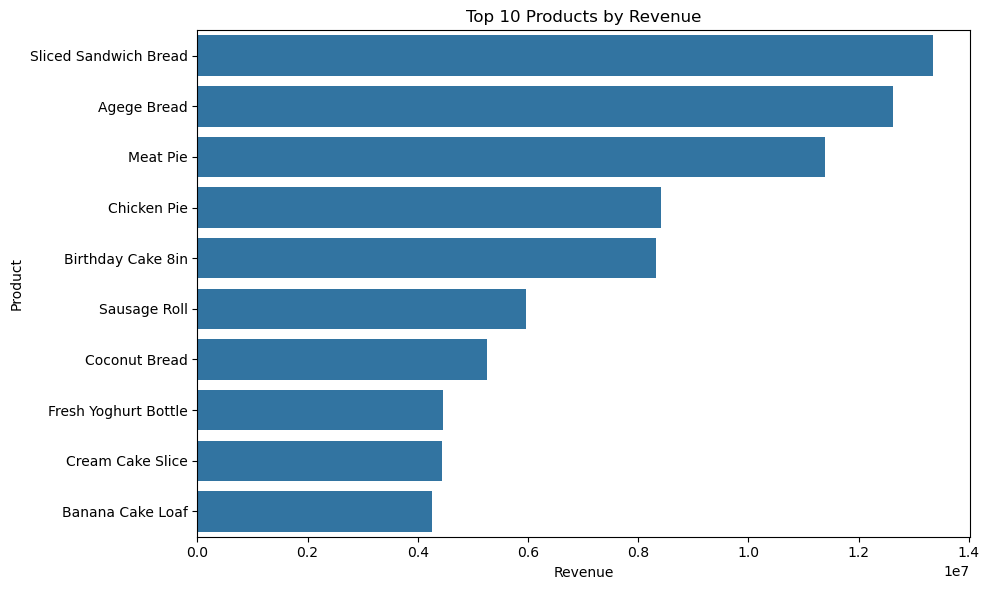

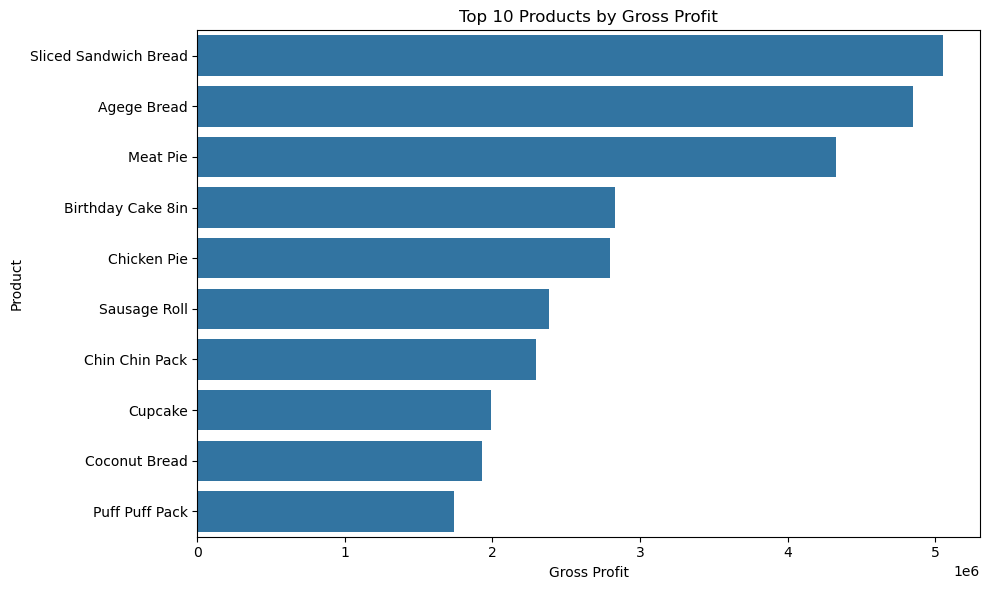

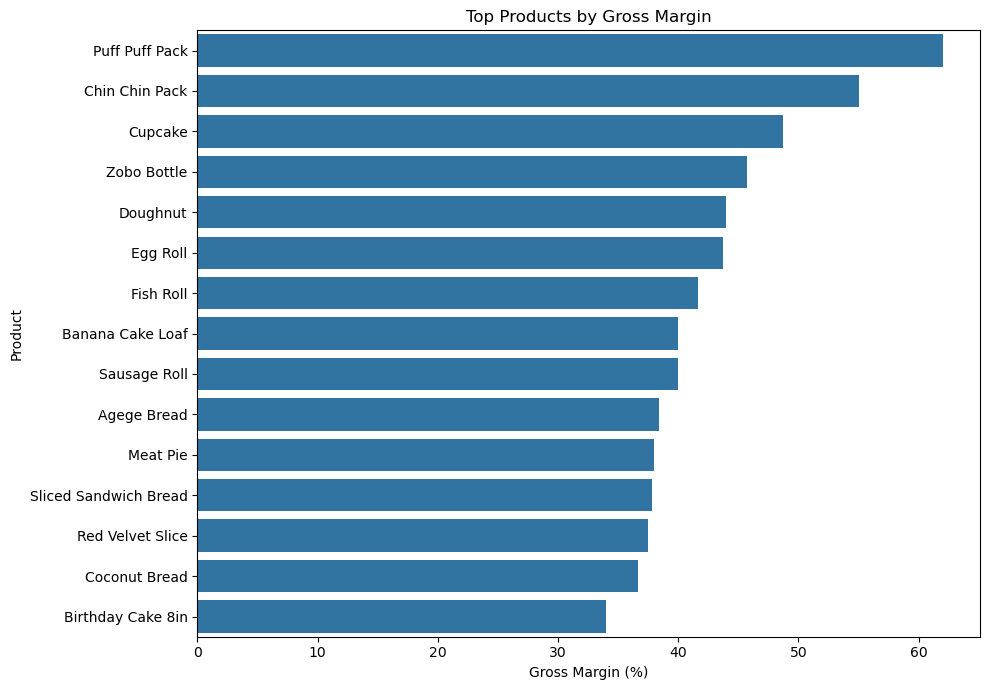

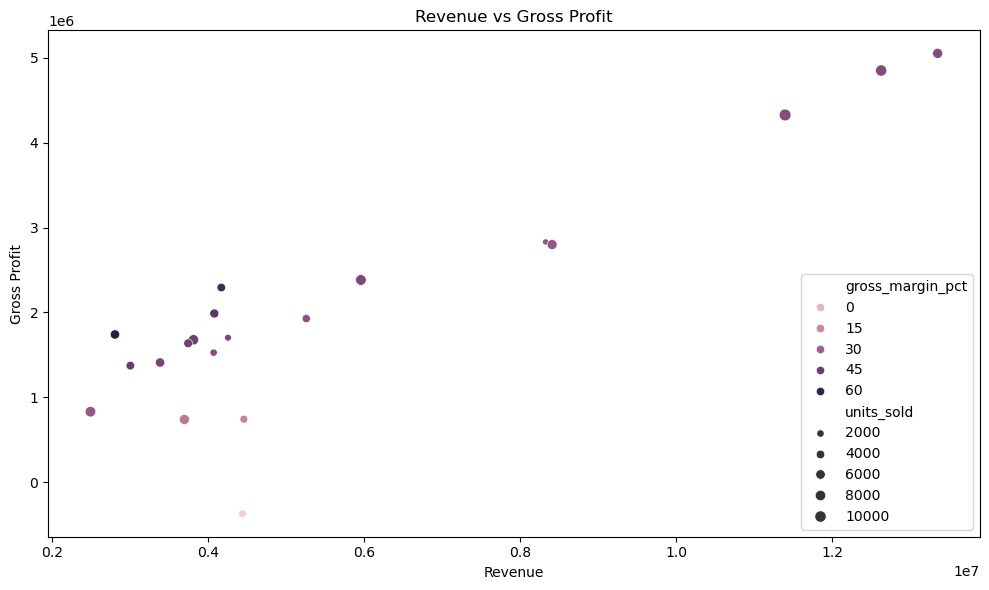


Waste columns: ['units_wasted_recorded', 'waste_missing']

TOP PRODUCTS BY WASTE
             product_name  waste_quantity
4             Chicken Pie          3140.0
6           Coconut Bread          1917.0
0             Agege Bread          1105.0
9                Doughnut           978.0
16           Sausage Roll           936.0
13               Meat Pie           906.0
17  Sliced Sandwich Bread           822.0
10               Egg Roll           652.0
11              Fish Roll           622.0
14         Puff Puff Pack           602.0

TOP PRODUCTS BY WASTE COST
             product_name  waste_quantity  waste_cost  gross_profit  \
4             Chicken Pie          3140.0   2512000.0     2799600.0   
6           Coconut Bread          1917.0   1821150.0     1928300.0   
7        Cream Cake Slice           527.0   1027650.0     -370050.0   
17  Sliced Sandwich Bread           822.0    945300.0     5051300.0   
0             Agege Bread          1105.0    861900.0     4849340.0   
1 

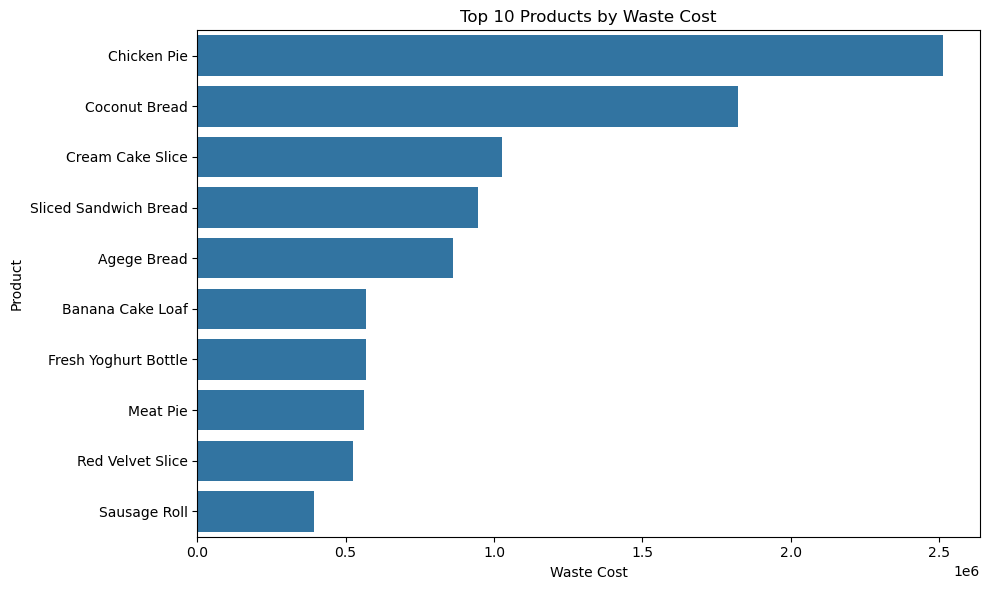


BAKERY PROFITABILITY SUMMARY
Revenue:            ₦113,745,112.00
COGS:               ₦72,283,110.00
Gross Profit:       ₦41,461,990.00
Gross Margin:       36.45%
Waste Cost:         ₦11,072,070.00
Profit After Waste: ₦30,389,920.00
Adjusted Margin:    26.72%

Stage 3 complete.
Saved: ../data/processed/product_profitability.csv


In [6]:
# ============================================================
# STAGE 3 — EDA & PROFITABILITY ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------------------------------------------------
# 1. LOAD CLEANED DATA
# ------------------------------------------------------------

transactions = pd.read_csv("../data/processed/transactions_clean.csv")
products = pd.read_csv("../data/processed/products_clean.csv")
production = pd.read_csv("../data/processed/production_log_clean.csv")

print("Transactions:", transactions.shape)
print("Products:", products.shape)
print("Production:", production.shape)


# ------------------------------------------------------------
# 2. STANDARDIZE COLUMN NAMES
# ------------------------------------------------------------

for df in [transactions, products, production]:
    df.columns = (
        df.columns
        .str.strip()
        .str.lower()
        .str.replace(" ", "_")
    )

print("\nTRANSACTION COLUMNS:")
print(transactions.columns.tolist())

print("\nPRODUCT COLUMNS:")
print(products.columns.tolist())

print("\nPRODUCTION COLUMNS:")
print(production.columns.tolist())


# ------------------------------------------------------------
# 3. IDENTIFY IMPORTANT COLUMNS
# ------------------------------------------------------------

qty_col = next(
    c for c in transactions.columns
    if "quantity" in c or c == "qty"
)

price_col = next(
    c for c in transactions.columns
    if "price" in c and "cost" not in c
)

product_col = next(
    c for c in transactions.columns
    if "product" in c
)

product_name_col = next(
    c for c in products.columns
    if "product" in c
)

cost_candidates = [
    c for c in products.columns
    if "cost" in c
]

cost_col = cost_candidates[0]

print("\nDetected columns:")
print("Product:", product_col)
print("Quantity:", qty_col)
print("Price:", price_col)
print("Cost:", cost_col)


# ------------------------------------------------------------
# 4. CALCULATE REVENUE
# ------------------------------------------------------------

transactions["revenue"] = (
    transactions[qty_col] *
    transactions[price_col]
)


# ------------------------------------------------------------
# 5. PRODUCT SALES SUMMARY
# ------------------------------------------------------------

sales = (
    transactions
    .groupby(product_col)
    .agg(
        units_sold=(qty_col, "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)


# ------------------------------------------------------------
# 6. ADD PRODUCT COST
# ------------------------------------------------------------

product_costs = products[
    [product_name_col, cost_col]
].copy()

product_costs = product_costs.rename(
    columns={
        product_name_col: product_col,
        cost_col: "unit_cost"
    }
)

sales = sales.merge(
    product_costs,
    on=product_col,
    how="left"
)


# ------------------------------------------------------------
# 7. PROFITABILITY METRICS
# ------------------------------------------------------------

sales["cogs"] = (
    sales["units_sold"] *
    sales["unit_cost"]
)

sales["gross_profit"] = (
    sales["revenue"] -
    sales["cogs"]
)

sales["gross_margin_pct"] = np.where(
    sales["revenue"] > 0,
    sales["gross_profit"] /
    sales["revenue"] * 100,
    0
)


# ------------------------------------------------------------
# 8. TOP PROFIT PRODUCTS
# ------------------------------------------------------------

print("\nTOP 10 PRODUCTS BY PROFIT")

print(
    sales[
        [
            product_col,
            "units_sold",
            "revenue",
            "cogs",
            "gross_profit",
            "gross_margin_pct"
        ]
    ]
    .sort_values("gross_profit", ascending=False)
    .head(10)
)


# ------------------------------------------------------------
# 9. LOWEST MARGIN PRODUCTS
# ------------------------------------------------------------

print("\nLOWEST MARGIN PRODUCTS")

print(
    sales[
        [
            product_col,
            "revenue",
            "gross_profit",
            "gross_margin_pct"
        ]
    ]
    .sort_values("gross_margin_pct")
    .head(10)
)


# ------------------------------------------------------------
# 10. TOP REVENUE PRODUCTS
# ------------------------------------------------------------

top_revenue = (
    sales
    .sort_values("revenue", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_revenue,
    x="revenue",
    y=product_col
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. TOP PROFIT PRODUCTS
# ------------------------------------------------------------

top_profit = (
    sales
    .sort_values("gross_profit", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_profit,
    x="gross_profit",
    y=product_col
)

plt.title("Top 10 Products by Gross Profit")
plt.xlabel("Gross Profit")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 12. GROSS MARGIN
# ------------------------------------------------------------

top_margin = (
    sales
    .sort_values("gross_margin_pct", ascending=False)
    .head(15)
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_margin,
    x="gross_margin_pct",
    y=product_col
)

plt.title("Top Products by Gross Margin")
plt.xlabel("Gross Margin (%)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. REVENUE VS PROFIT
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=sales,
    x="revenue",
    y="gross_profit",
    size="units_sold",
    hue="gross_margin_pct"
)

plt.title("Revenue vs Gross Profit")
plt.xlabel("Revenue")
plt.ylabel("Gross Profit")
plt.tight_layout()
plt.show()


# ============================================================
# WASTE ANALYSIS
# ============================================================

# ------------------------------------------------------------
# 14. FIND WASTE COLUMN
# ------------------------------------------------------------

waste_cols = [
    c for c in production.columns
    if "waste" in c or "discard" in c
]

print("\nWaste columns:", waste_cols)

waste_col = waste_cols[0]


# ------------------------------------------------------------
# 15. FIND PRODUCTION PRODUCT COLUMN
# ------------------------------------------------------------

prod_product_col = next(
    c for c in production.columns
    if "product" in c
)


# ------------------------------------------------------------
# 16. WASTE BY PRODUCT
# ------------------------------------------------------------

waste = (
    production
    .groupby(prod_product_col)[waste_col]
    .sum()
    .reset_index()
)

waste.columns = [
    product_col,
    "waste_quantity"
]

waste = waste.sort_values(
    "waste_quantity",
    ascending=False
)

print("\nTOP PRODUCTS BY WASTE")

print(waste.head(10))


# ------------------------------------------------------------
# 17. MERGE WASTE WITH PROFITABILITY
# ------------------------------------------------------------

analysis = sales.merge(
    waste,
    on=product_col,
    how="left"
)

analysis["waste_quantity"] = (
    analysis["waste_quantity"]
    .fillna(0)
)

analysis["waste_cost"] = (
    analysis["waste_quantity"] *
    analysis["unit_cost"]
)

analysis["adjusted_profit"] = (
    analysis["gross_profit"] -
    analysis["waste_cost"]
)

analysis["adjusted_margin_pct"] = np.where(
    analysis["revenue"] > 0,
    analysis["adjusted_profit"] /
    analysis["revenue"] * 100,
    0
)


# ------------------------------------------------------------
# 18. WASTE IMPACT
# ------------------------------------------------------------

print("\nTOP PRODUCTS BY WASTE COST")

print(
    analysis[
        [
            product_col,
            "waste_quantity",
            "waste_cost",
            "gross_profit",
            "adjusted_profit"
        ]
    ]
    .sort_values("waste_cost", ascending=False)
    .head(10)
)


# ------------------------------------------------------------
# 19. WASTE VISUALIZATION
# ------------------------------------------------------------

top_waste = (
    analysis
    .sort_values("waste_cost", ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_waste,
    x="waste_cost",
    y=product_col
)

plt.title("Top 10 Products by Waste Cost")
plt.xlabel("Waste Cost")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 20. OVERALL BUSINESS SUMMARY
# ------------------------------------------------------------

total_revenue = analysis["revenue"].sum()
total_cogs = analysis["cogs"].sum()
total_waste_cost = analysis["waste_cost"].sum()
total_profit = analysis["gross_profit"].sum()
adjusted_profit = analysis["adjusted_profit"].sum()

overall_margin = (
    total_profit / total_revenue * 100
    if total_revenue > 0 else 0
)

adjusted_margin = (
    adjusted_profit / total_revenue * 100
    if total_revenue > 0 else 0
)

print("\n" + "=" * 50)
print("BAKERY PROFITABILITY SUMMARY")
print("=" * 50)

print(f"Revenue:            ₦{total_revenue:,.2f}")
print(f"COGS:               ₦{total_cogs:,.2f}")
print(f"Gross Profit:       ₦{total_profit:,.2f}")
print(f"Gross Margin:       {overall_margin:.2f}%")
print(f"Waste Cost:         ₦{total_waste_cost:,.2f}")
print(f"Profit After Waste: ₦{adjusted_profit:,.2f}")
print(f"Adjusted Margin:    {adjusted_margin:.2f}%")


# ------------------------------------------------------------
# 21. SAVE STAGE 3 DATASET
# ------------------------------------------------------------

analysis.to_csv(
    "../data/processed/product_profitability.csv",
    index=False
)

print("\nStage 3 complete.")
print("Saved: ../data/processed/product_profitability.csv")